| Column              | Data Type غالبًا | المعنى              |
| ------------------- | ---------------- | ------------------- |
| `Posted On`         | Date             | تاريخ نشر الإعلان   |
| `BHK`               | Numerical        | عدد غرف النوم       |
| `Rent`              | Numerical        | قيمة الإيجار        |
| `Size`              | Numerical        | مساحة الشقة         |
| `Floor`             | Categorical/Text | الدور               |
| `Area Type`         | Categorical      | نوع المنطقة/المساحة |
| `Area Locality`     | Categorical      | اسم المنطقة         |
| `City`              | Categorical      | المدينة             |
| `Furnishing Status` | Categorical      | حالة الفرش          |
| `Tenant Preferred`  | Categorical      | نوع المستأجر المفضل |
| `Bathroom`          | Numerical        | عدد الحمامات        |
| `Point of Contact`  | Categorical      | طريقة/جهة التواصل   |


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [3]:
df= pd.read_csv('/content/House_Rent_Dataset.csv')

In [ ]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   str    
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   str    
 5   Area Type          4739 non-null   str    
 6   Area Locality      4746 non-null   str    
 7   City               4746 non-null   str    
 8   Furnishing Status  4746 non-null   str    
 9   Tenant Preferred   4746 non-null   str    
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 445.1 KB


In [ ]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [ ]:
df.describe(include='object')

C:\Users\Right Click\AppData\Local\Temp\ipykernel_7532\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Posted On,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Point of Contact
count,4746,4746,4739,4746,4746,4746,4746,4746
unique,81,480,3,2235,6,3,3,3
top,7/6/2022,1 out of 2,Super Area,Bandra West,Mumbai,Semi-Furnished,Bachelors/Family,Contact Owner
freq,311,379,2442,37,972,2251,3444,3216


In [ ]:
df['Floor'].unique()

<StringArray>
[ 'Ground out of 2',       '1 out of 3',       '1 out of 2',
  'Ground out of 1',  'Ground out of 4',       '1 out of 4',
       '1 out of 1',  'Ground out of 3',       '2 out of 3',
       '4 out of 5',
 ...
      '4 out of 26',     '24 out of 33',      '4 out of 17',
      '1 out of 35',     '11 out of 35', 'Ground out of 15',
 'Ground out of 27',     '15 out of 30',     '12 out of 30',
     '23 out of 34']
Length: 480, dtype: str

In [ ]:
# 2. Parse Floor ("3 out of 5" -> current_floor=3, total_floors=5)
def parse_floor(s):
    parts = str(s).split(" out of ")
    cur = parts[0].strip()
    mapping = {"Ground": 0, "Upper Basement": -1, "Lower Basement": -2}
    cur = mapping[cur] if cur in mapping else pd.to_numeric(cur, errors="coerce")
    total = pd.to_numeric(parts[1], errors="coerce") if len(parts) > 1 else np.nan
    return pd.Series([cur, total])

df[["current_floor", "total_floors"]] = df["Floor"].apply(parse_floor)


In [ ]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,0.0,2.0
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,1.0,3.0
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,1.0,3.0
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,1.0,2.0
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,1.0,2.0


In [ ]:
df = df.drop(columns=["Floor", "Posted On", "Area Locality"])

In [ ]:
y = df['Rent']
X = df.drop('Rent', axis=1)

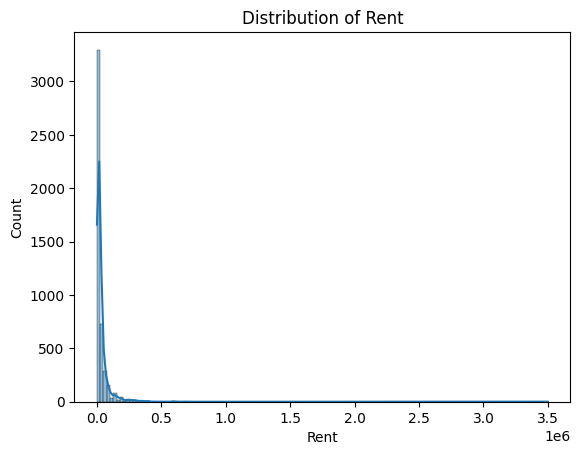

In [ ]:
sns.histplot(df['Rent'], kde=True)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.show()


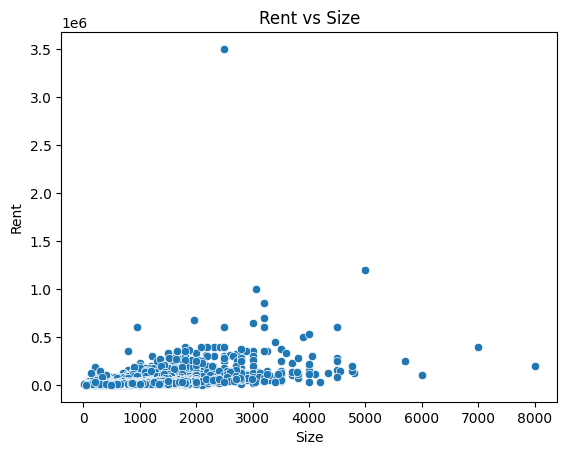

In [ ]:
sns.scatterplot(data=df, x='Size', y='Rent')
plt.title('Rent vs Size')
plt.show()

In [ ]:
df[df['Rent']>3000000]

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
1837,3,3500000.0,2500.0,Carpet Area,Bangalore,Semi-Furnished,Bachelors,3.0,Contact Agent,4.0,4.0


In [ ]:
df[df['City']=='Bangalore'].sort_values('Rent', ascending=False)

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
1837,3,3500000.0,2500.0,Carpet Area,Bangalore,Semi-Furnished,Bachelors,3.0,Contact Agent,4.0,4.0
1718,4,380000.0,3500.0,Carpet Area,Bangalore,Semi-Furnished,Bachelors,5.0,Contact Agent,2.0,4.0
2209,3,280000.0,2800.0,Carpet Area,Bangalore,Furnished,Bachelors/Family,3.0,Contact Agent,6.0,30.0
2048,4,250000.0,5700.0,Carpet Area,Bangalore,Semi-Furnished,Bachelors/Family,4.0,Contact Agent,24.0,25.0
2186,4,190000.0,4000.0,Super Area,Bangalore,Furnished,Bachelors/Family,5.0,Contact Owner,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...
2293,1,4000.0,250.0,Super Area,Bangalore,Unfurnished,Bachelors/Family,1.0,Contact Owner,0.0,2.0
1572,1,4000.0,650.0,Super Area,Bangalore,Unfurnished,Bachelors/Family,1.0,Contact Owner,1.0,2.0
2325,1,4000.0,100.0,Super Area,Bangalore,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,2.0,3.0
2082,1,4000.0,250.0,Super Area,Bangalore,Unfurnished,Bachelors/Family,1.0,Contact Owner,2.0,3.0


In [ ]:
df.iloc[1837, df.columns.get_loc('Rent')] = 350000

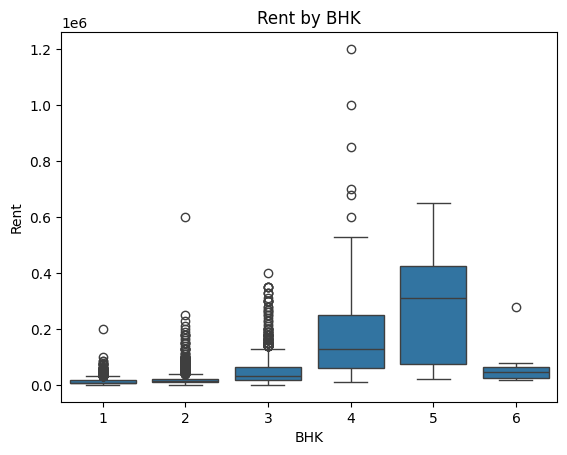

In [ ]:
sns.boxplot(data=df, x='BHK', y='Rent')
plt.title('Rent by BHK')
plt.show()

In [ ]:
df[df['BHK']==1].sort_values('Rent', ascending=False)

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
4185,1,200000.0,8000.0,Super Area,Hyderabad,Unfurnished,Bachelors/Family,10.0,Contact Owner,0.0,4.0
914,1,100000.0,400.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,1.0,Contact Agent,9.0,10.0
1269,1,85000.0,650.0,Super Area,Mumbai,Furnished,Bachelors/Family,2.0,Contact Owner,3.0,8.0
1216,1,85000.0,695.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,2.0,Contact Agent,2.0,7.0
1320,1,80000.0,560.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,1.0,Contact Agent,1.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...
471,1,1800.0,500.0,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,0.0,1.0
285,1,1500.0,200.0,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,0.0,2.0
26,1,NaN,355.0,Carpet Area,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Agent,1.0,1.0
55,1,NaN,NaN,Carpet Area,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,0.0,2.0


In [ ]:
df.drop(4185, inplace=True)

In [ ]:
df[df['BHK']==2].sort_values('Rent', ascending=False)

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
3656,2,600000.0,950.0,Carpet Area,Chennai,Unfurnished,Bachelors,2.0,Contact Owner,1.0,1.0
1196,2,250000.0,1300.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,2.0,Contact Agent,-1.0,10.0
1029,2,230000.0,1000.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,2.0,Contact Agent,2.0,7.0
595,2,210000.0,1000.0,Carpet Area,Mumbai,Unfurnished,Bachelors,2.0,Contact Agent,4.0,8.0
1089,2,200000.0,1000.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,2.0,Contact Agent,7.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...
177,2,4000.0,600.0,Carpet Area,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,1.0,2.0
226,2,3500.0,500.0,Carpet Area,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,4.0,5.0
146,2,2200.0,550.0,Super Area,Kolkata,Furnished,Bachelors/Family,1.0,Contact Owner,2.0,3.0
2475,2,2000.0,60.0,Super Area,Delhi,Unfurnished,Bachelors/Family,1.0,Contact Owner,1.0,1.0


In [ ]:
df.iloc[3656, df.columns.get_loc('Rent')] = 60000

In [ ]:
df[df['BHK']==4].sort_values('Rent', ascending=False).head(10) #The outliers are all from the same city, which means the data is real.


,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
1001,4,1200000.0,5000.0,Carpet Area,Mumbai,Semi-Furnished,Bachelors/Family,4.0,Contact Agent,4.0,15.0
827,4,1000000.0,3064.0,Carpet Area,Mumbai,Semi-Furnished,Family,4.0,Contact Agent,18.0,45.0
1329,4,850000.0,3200.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent,2.0,4.0
1459,4,700000.0,3200.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent,24.0,24.0
1484,4,680000.0,1962.0,Carpet Area,Mumbai,Semi-Furnished,Bachelors/Family,5.0,Contact Agent,18.0,20.0
726,4,600000.0,2500.0,Carpet Area,Mumbai,Semi-Furnished,Bachelors/Family,4.0,Contact Agent,12.0,13.0
2750,4,530000.0,4000.0,Carpet Area,Delhi,Semi-Furnished,Bachelors/Family,5.0,Contact Agent,3.0,4.0
1344,4,400000.0,2500.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent,5.0,12.0
1431,4,400000.0,2080.0,Carpet Area,Mumbai,Semi-Furnished,Bachelors/Family,5.0,Contact Agent,34.0,46.0
702,4,400000.0,2200.0,Carpet Area,Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent,6.0,10.0


In [ ]:
df[df['BHK']==6].sort_values('Rent', ascending=False)

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,current_floor,total_floors
3320,6,280000.0,4500.0,Carpet Area,Chennai,Semi-Furnished,Bachelors,5.0,Contact Agent,0.0,1.0
4648,6,80000.0,4500.0,Super Area,Hyderabad,Semi-Furnished,Bachelors/Family,6.0,Contact Owner,1.0,2.0
4350,6,60000.0,2800.0,Super Area,Hyderabad,Furnished,Bachelors/Family,7.0,Contact Owner,0.0,3.0
3584,6,60000.0,1800.0,Super Area,Chennai,Furnished,Bachelors/Family,6.0,Contact Owner,1.0,3.0
4518,6,35000.0,3400.0,Super Area,Hyderabad,Unfurnished,Bachelors/Family,7.0,Contact Owner,0.0,2.0
4696,6,30000.0,4200.0,Super Area,Hyderabad,Semi-Furnished,Bachelors/Family,5.0,Contact Owner,0.0,2.0
83,6,20000.0,1000.0,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,1.0,1.0
4479,6,20000.0,2400.0,Super Area,Hyderabad,Unfurnished,Family,4.0,Contact Owner,0.0,1.0


In [ ]:
df.drop(3320, inplace=True)

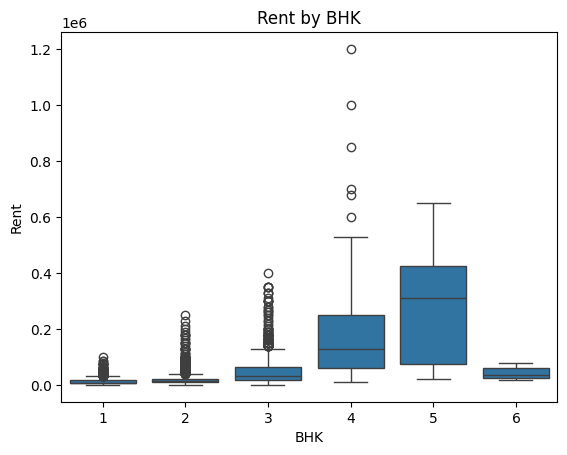

In [ ]:
sns.boxplot(data=df, x='BHK', y='Rent')
plt.title('Rent by BHK')
plt.show()

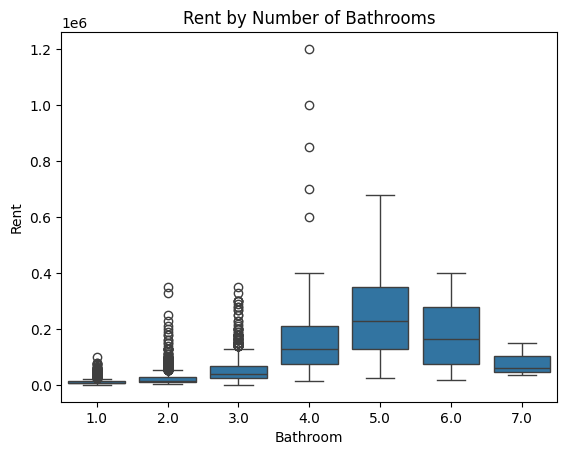

In [ ]:
sns.boxplot(data=df, x='Bathroom', y='Rent')
plt.title('Rent by Number of Bathrooms')
plt.show()

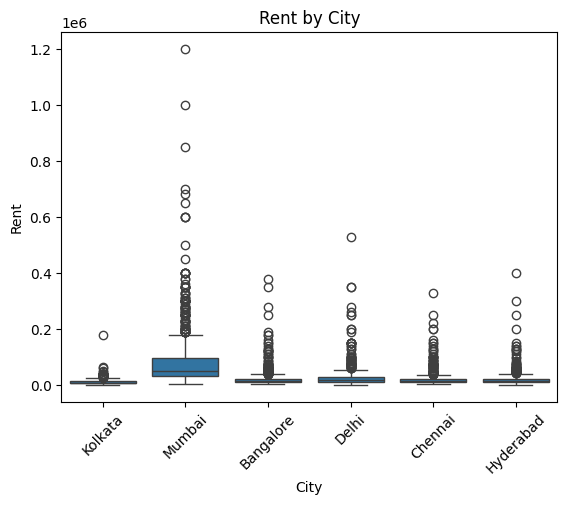

In [ ]:
sns.boxplot(data=df, x='City', y='Rent')
plt.xticks(rotation=45)
plt.title('Rent by City')
plt.show()

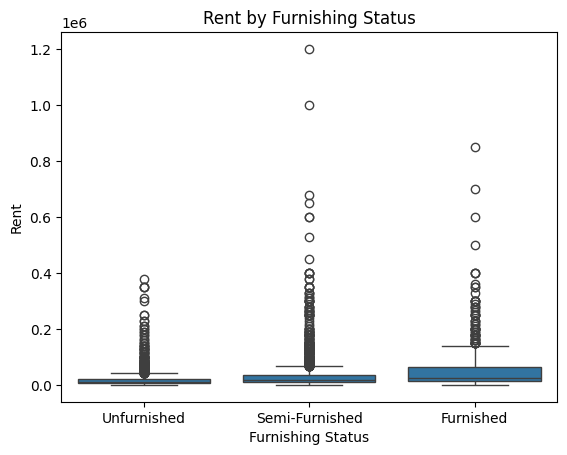

In [ ]:
sns.boxplot(data=df, x='Furnishing Status', y='Rent')
plt.title('Rent by Furnishing Status')
plt.show()

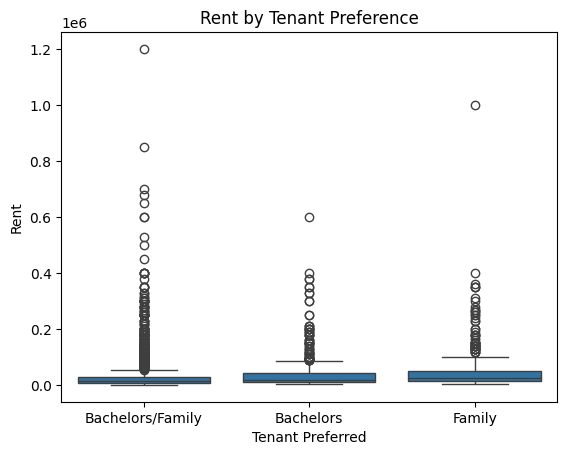

In [ ]:
sns.boxplot(data=df, x='Tenant Preferred', y='Rent')
plt.title('Rent by Tenant Preference')
plt.show()

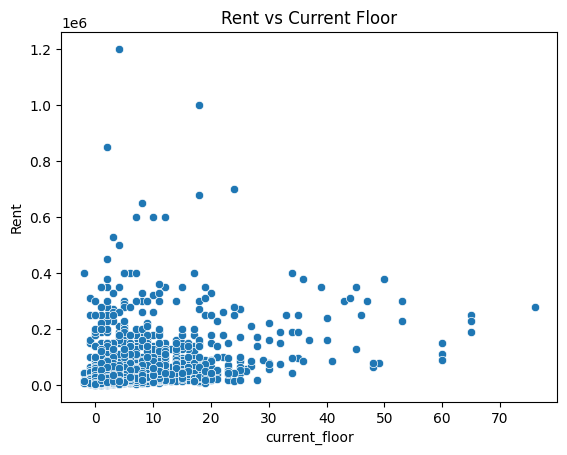

In [ ]:
sns.scatterplot(data=df, x='current_floor', y='Rent')
plt.title('Rent vs Current Floor')
plt.show()

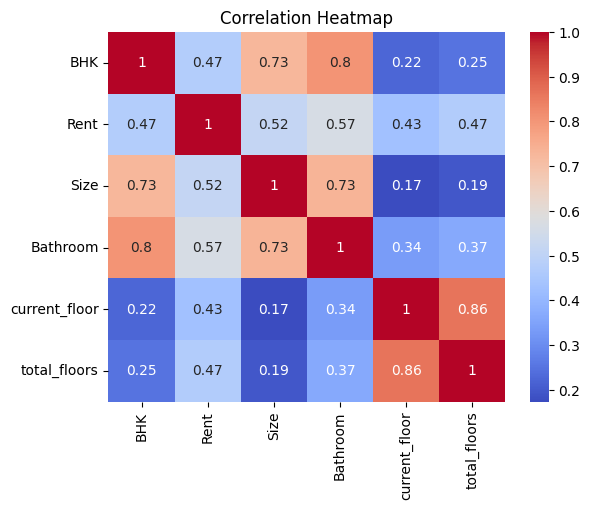

In [ ]:
numeric_df = df.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
df.dropna(inplace=True)

In [ ]:
#  Split (target is log-transformed to reduce skew)

X = df.drop(columns="Rent")
y = np.log1p(df["Rent"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [ ]:
#  Fill any missing floor values (fit on train only)
for col in ["current_floor", "total_floors"]:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

In [ ]:
#Encode categoricals
cat_cols = ["Area Type", "City", "Furnishing Status",
            "Tenant Preferred", "Point of Contact"]
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [ ]:
#Scale numeric columns (fit on train only)
num_cols = ["BHK", "Size", "Bathroom", "current_floor", "total_floors"]
scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


In [ ]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [ ]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

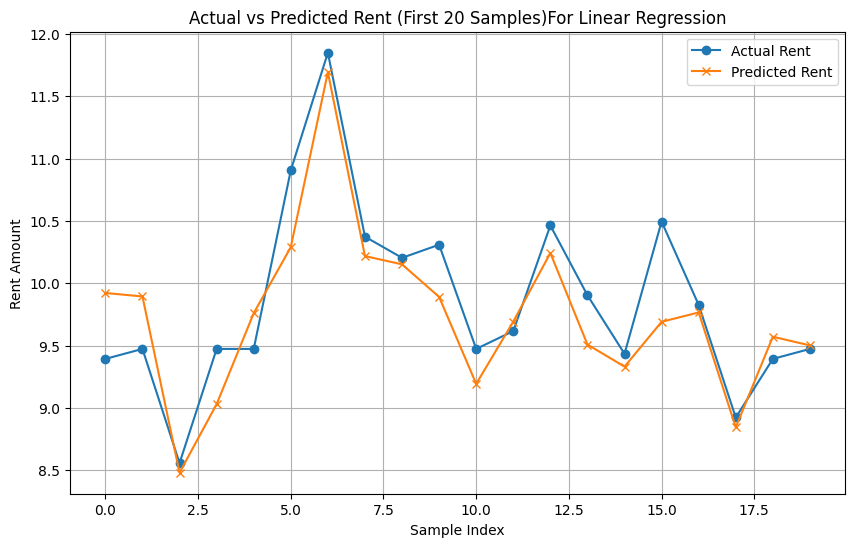

  7%|▋         | 1/15 [00:00<00:02,  4.97it/s]

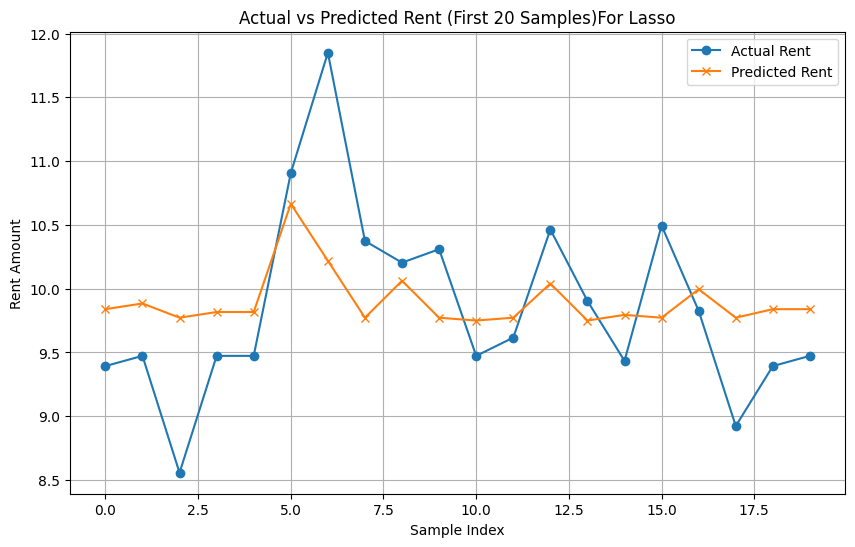

 13%|█▎        | 2/15 [00:00<00:03,  3.92it/s]

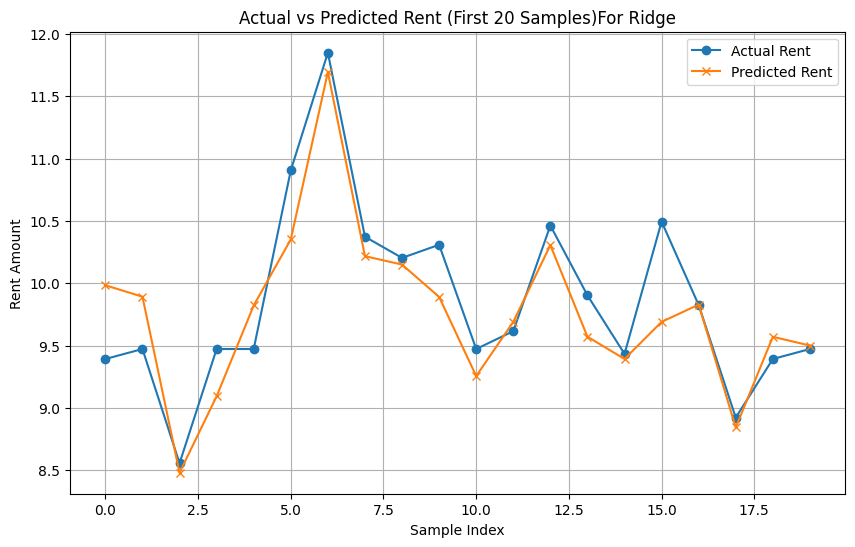

 20%|██        | 3/15 [00:00<00:02,  4.72it/s]

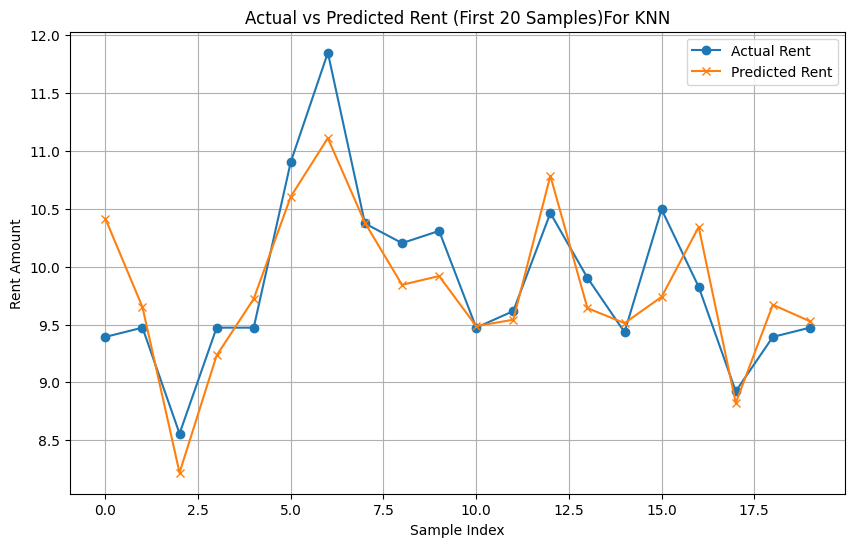

 27%|██▋       | 4/15 [00:01<00:02,  3.73it/s]

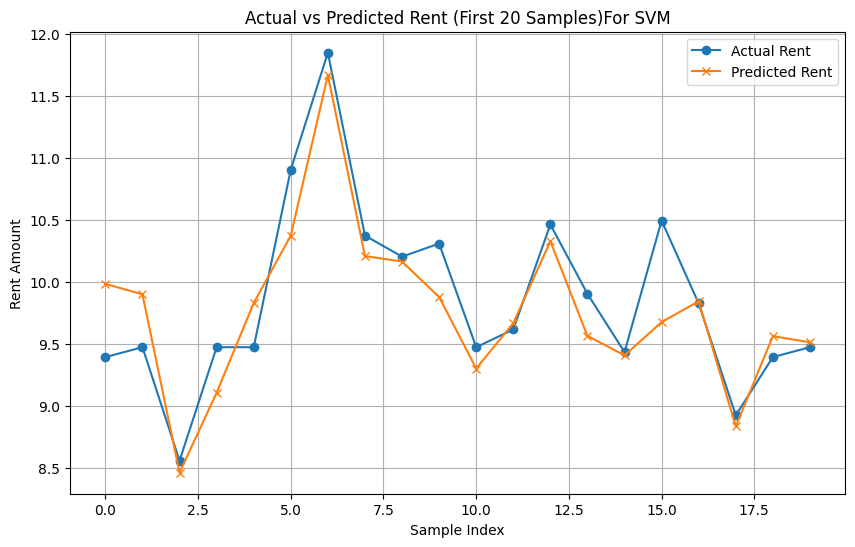

 33%|███▎      | 5/15 [01:43<06:11, 37.12s/it]

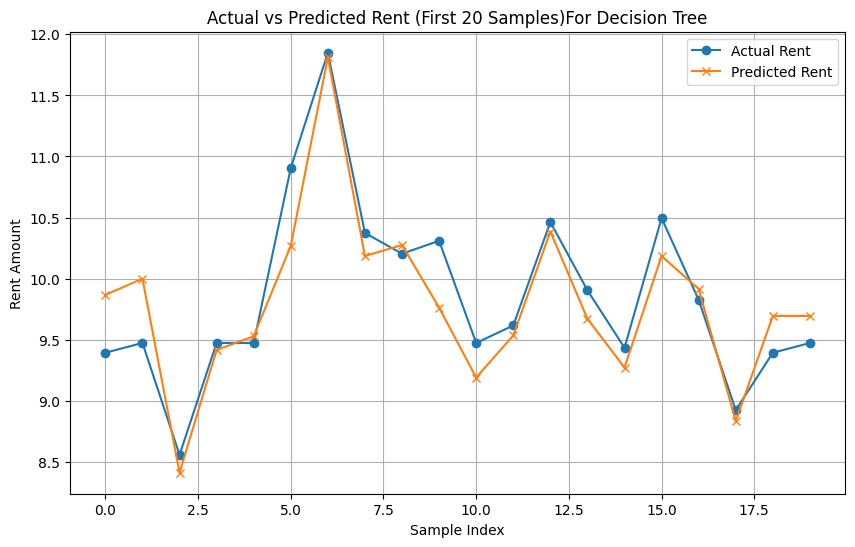

 40%|████      | 6/15 [01:44<03:42, 24.73s/it]

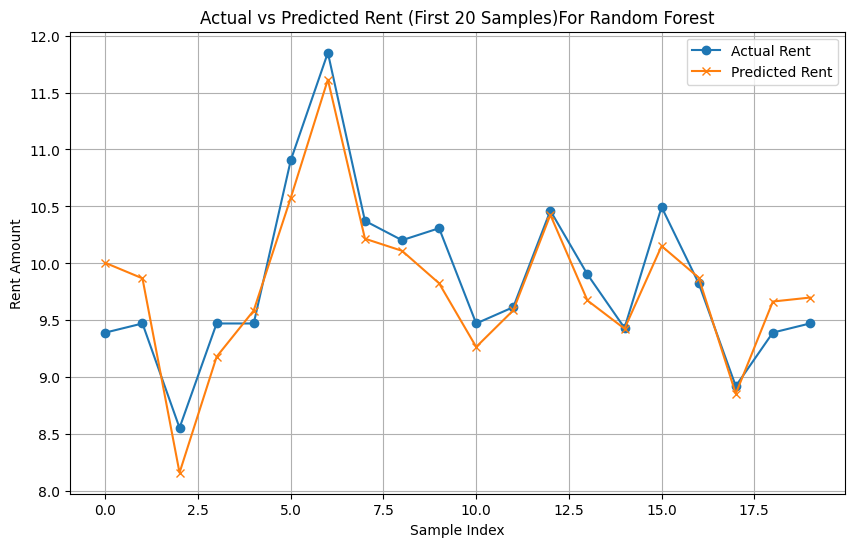

 47%|████▋     | 7/15 [01:45<02:15, 17.00s/it]

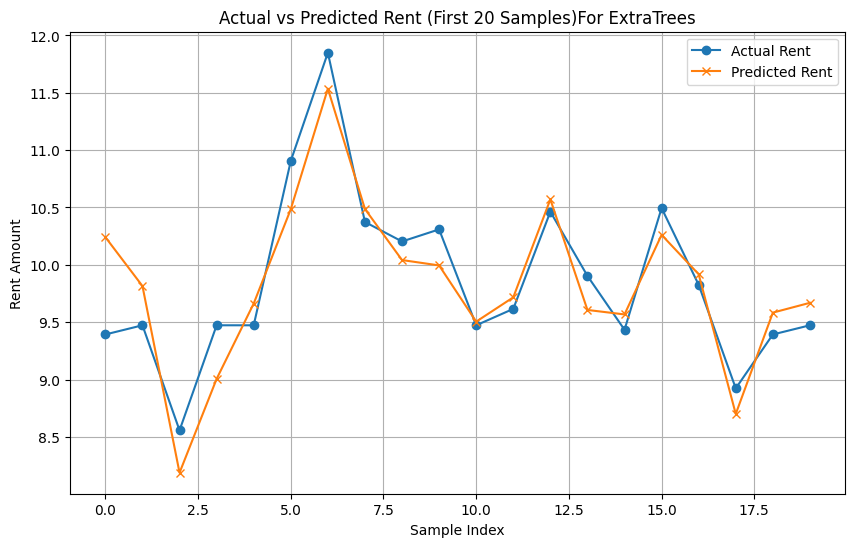

 53%|█████▎    | 8/15 [01:47<01:26, 12.32s/it]

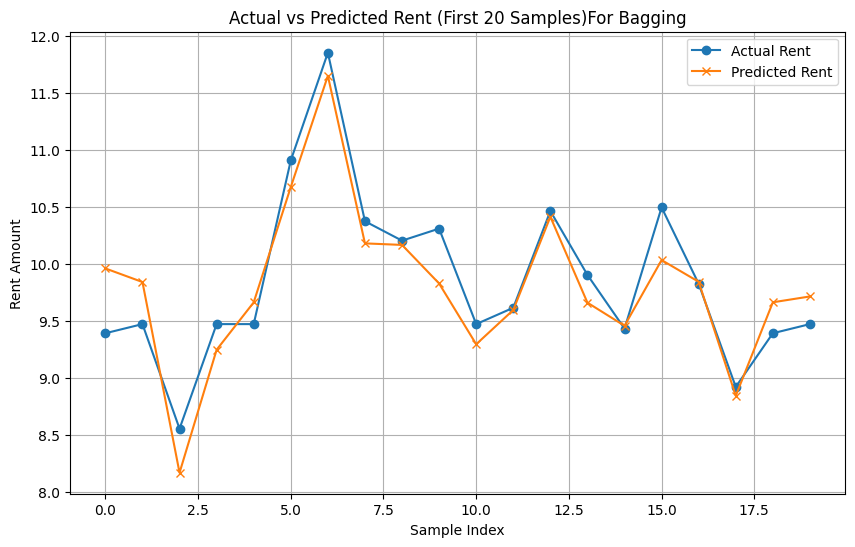

 60%|██████    | 9/15 [01:48<00:52,  8.69s/it]

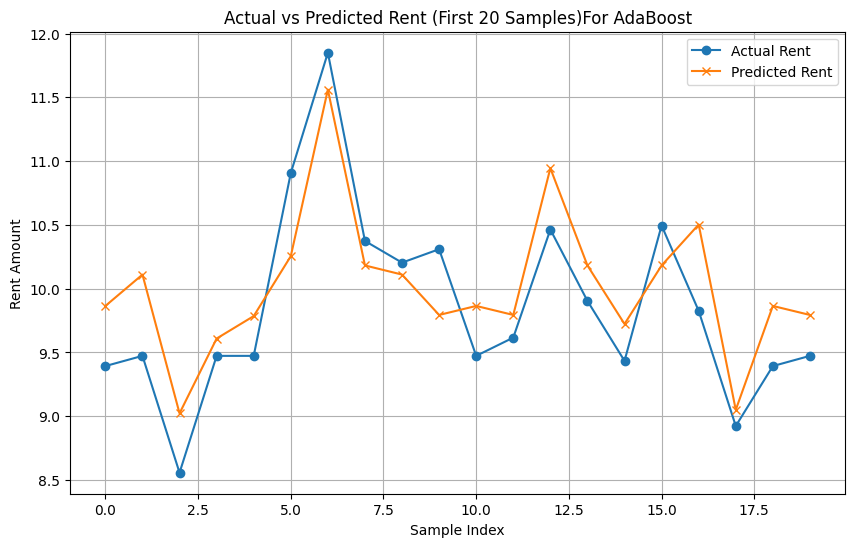

 67%|██████▋   | 10/15 [01:48<00:30,  6.10s/it]

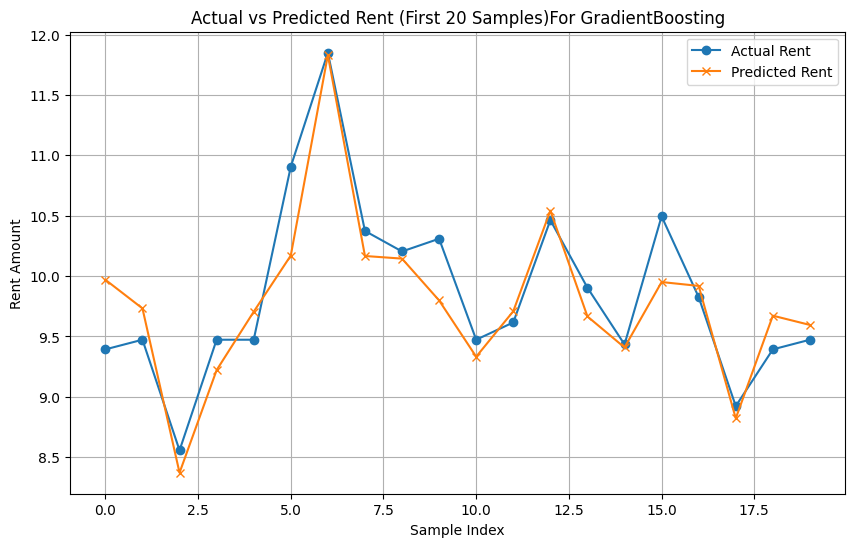

 73%|███████▎  | 11/15 [01:49<00:17,  4.41s/it]

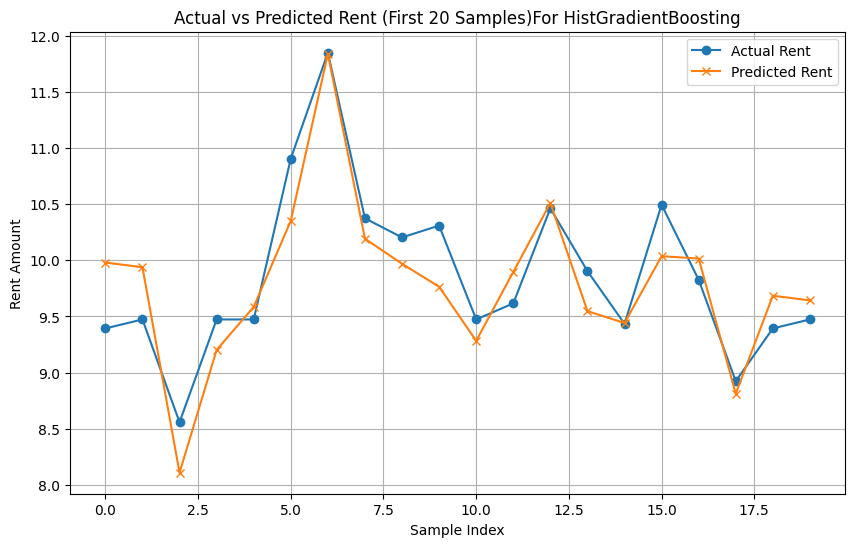

 80%|████████  | 12/15 [01:50<00:10,  3.43s/it]

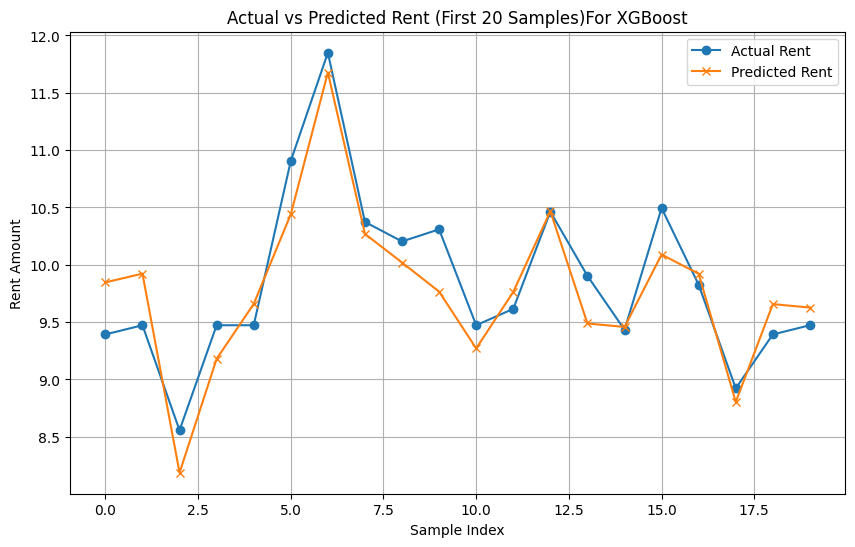

 87%|████████▋ | 13/15 [01:50<00:05,  2.53s/it]

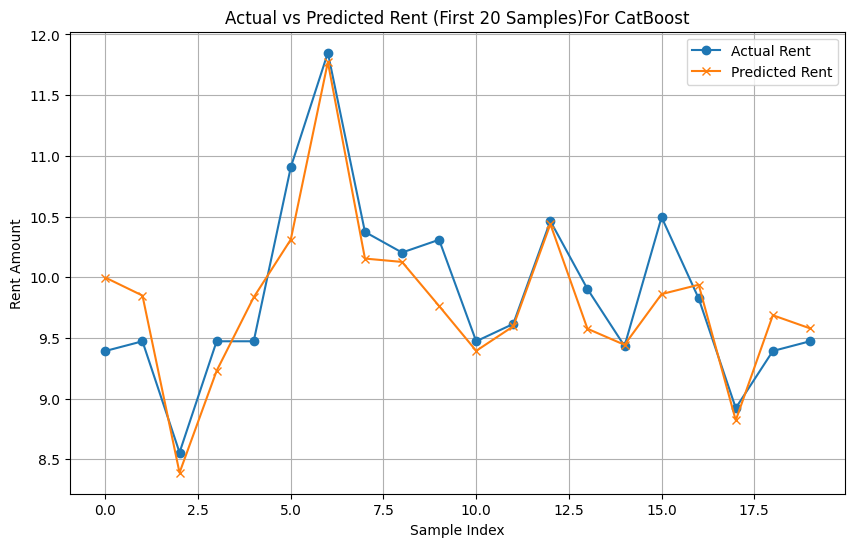

 93%|█████████▎| 14/15 [01:51<00:01,  1.92s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000122 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 380
[LightGBM] [Info] Number of data points in the train set: 3776, number of used features: 17
[LightGBM] [Info] Start training from score 9.884926


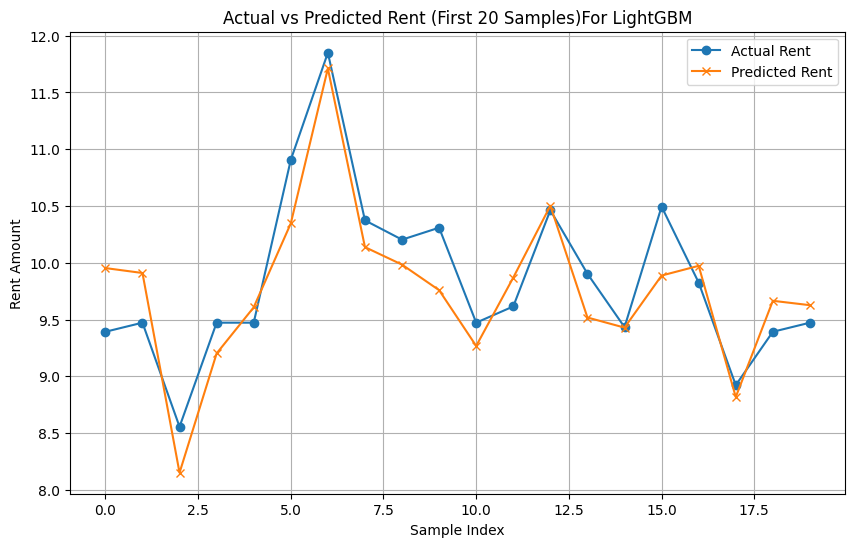

100%|██████████| 15/15 [01:51<00:00,  7.44s/it]


In [ ]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [ ]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [ ]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,0.260456,0.292195,0.120789,0.147761,0.347547,0.384397,0.863471,0.817562
GradientBoosting,0.264654,0.297089,0.125141,0.152359,0.353752,0.390332,0.858553,0.811885
HistGradientBoosting,0.226822,0.297319,0.091134,0.154368,0.301884,0.392897,0.896991,0.809405
LightGBM,0.225189,0.297433,0.089891,0.155340,0.299819,0.394132,0.898395,0.808204
XGBoost,0.207225,0.298273,0.074367,0.156137,0.272703,0.395142,0.915942,0.807220
Bagging,0.202139,0.301642,0.069216,0.159107,0.263090,0.398882,0.921764,0.803553
Random Forest,0.201142,0.301344,0.069119,0.159184,0.262904,0.398978,0.921875,0.803459
SVM,0.291917,0.304152,0.155962,0.162706,0.394920,0.403368,0.823715,0.799110
Voting,0.134055,0.297433,0.032671,0.155340,0.180750,0.394132,0.963072,0.799088
Simple Voting,0.134055,0.297433,0.032671,0.155340,0.180750,0.394132,0.963072,0.799088


<Axes: >

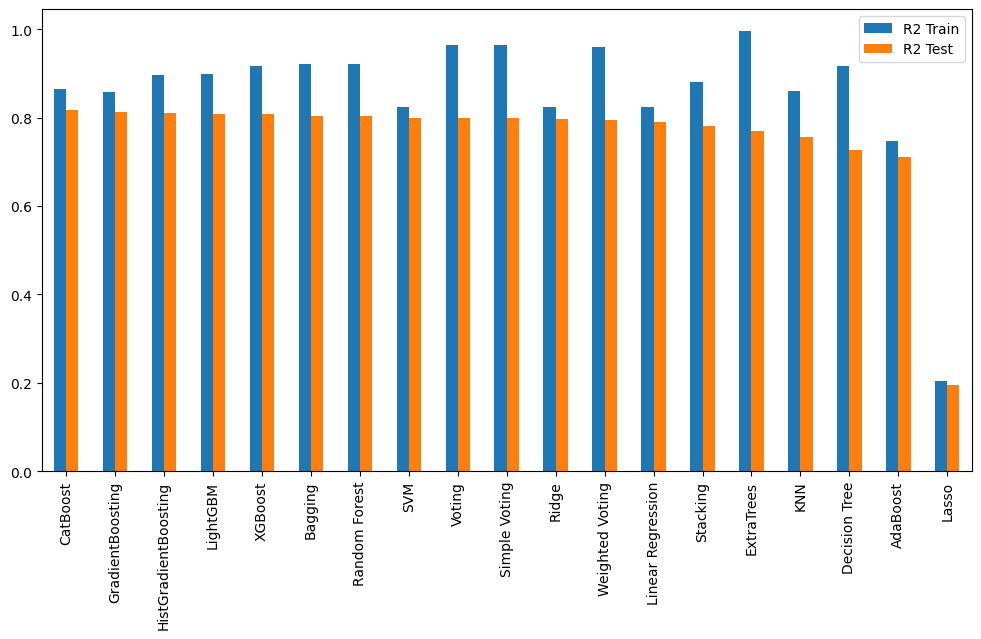

In [ ]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

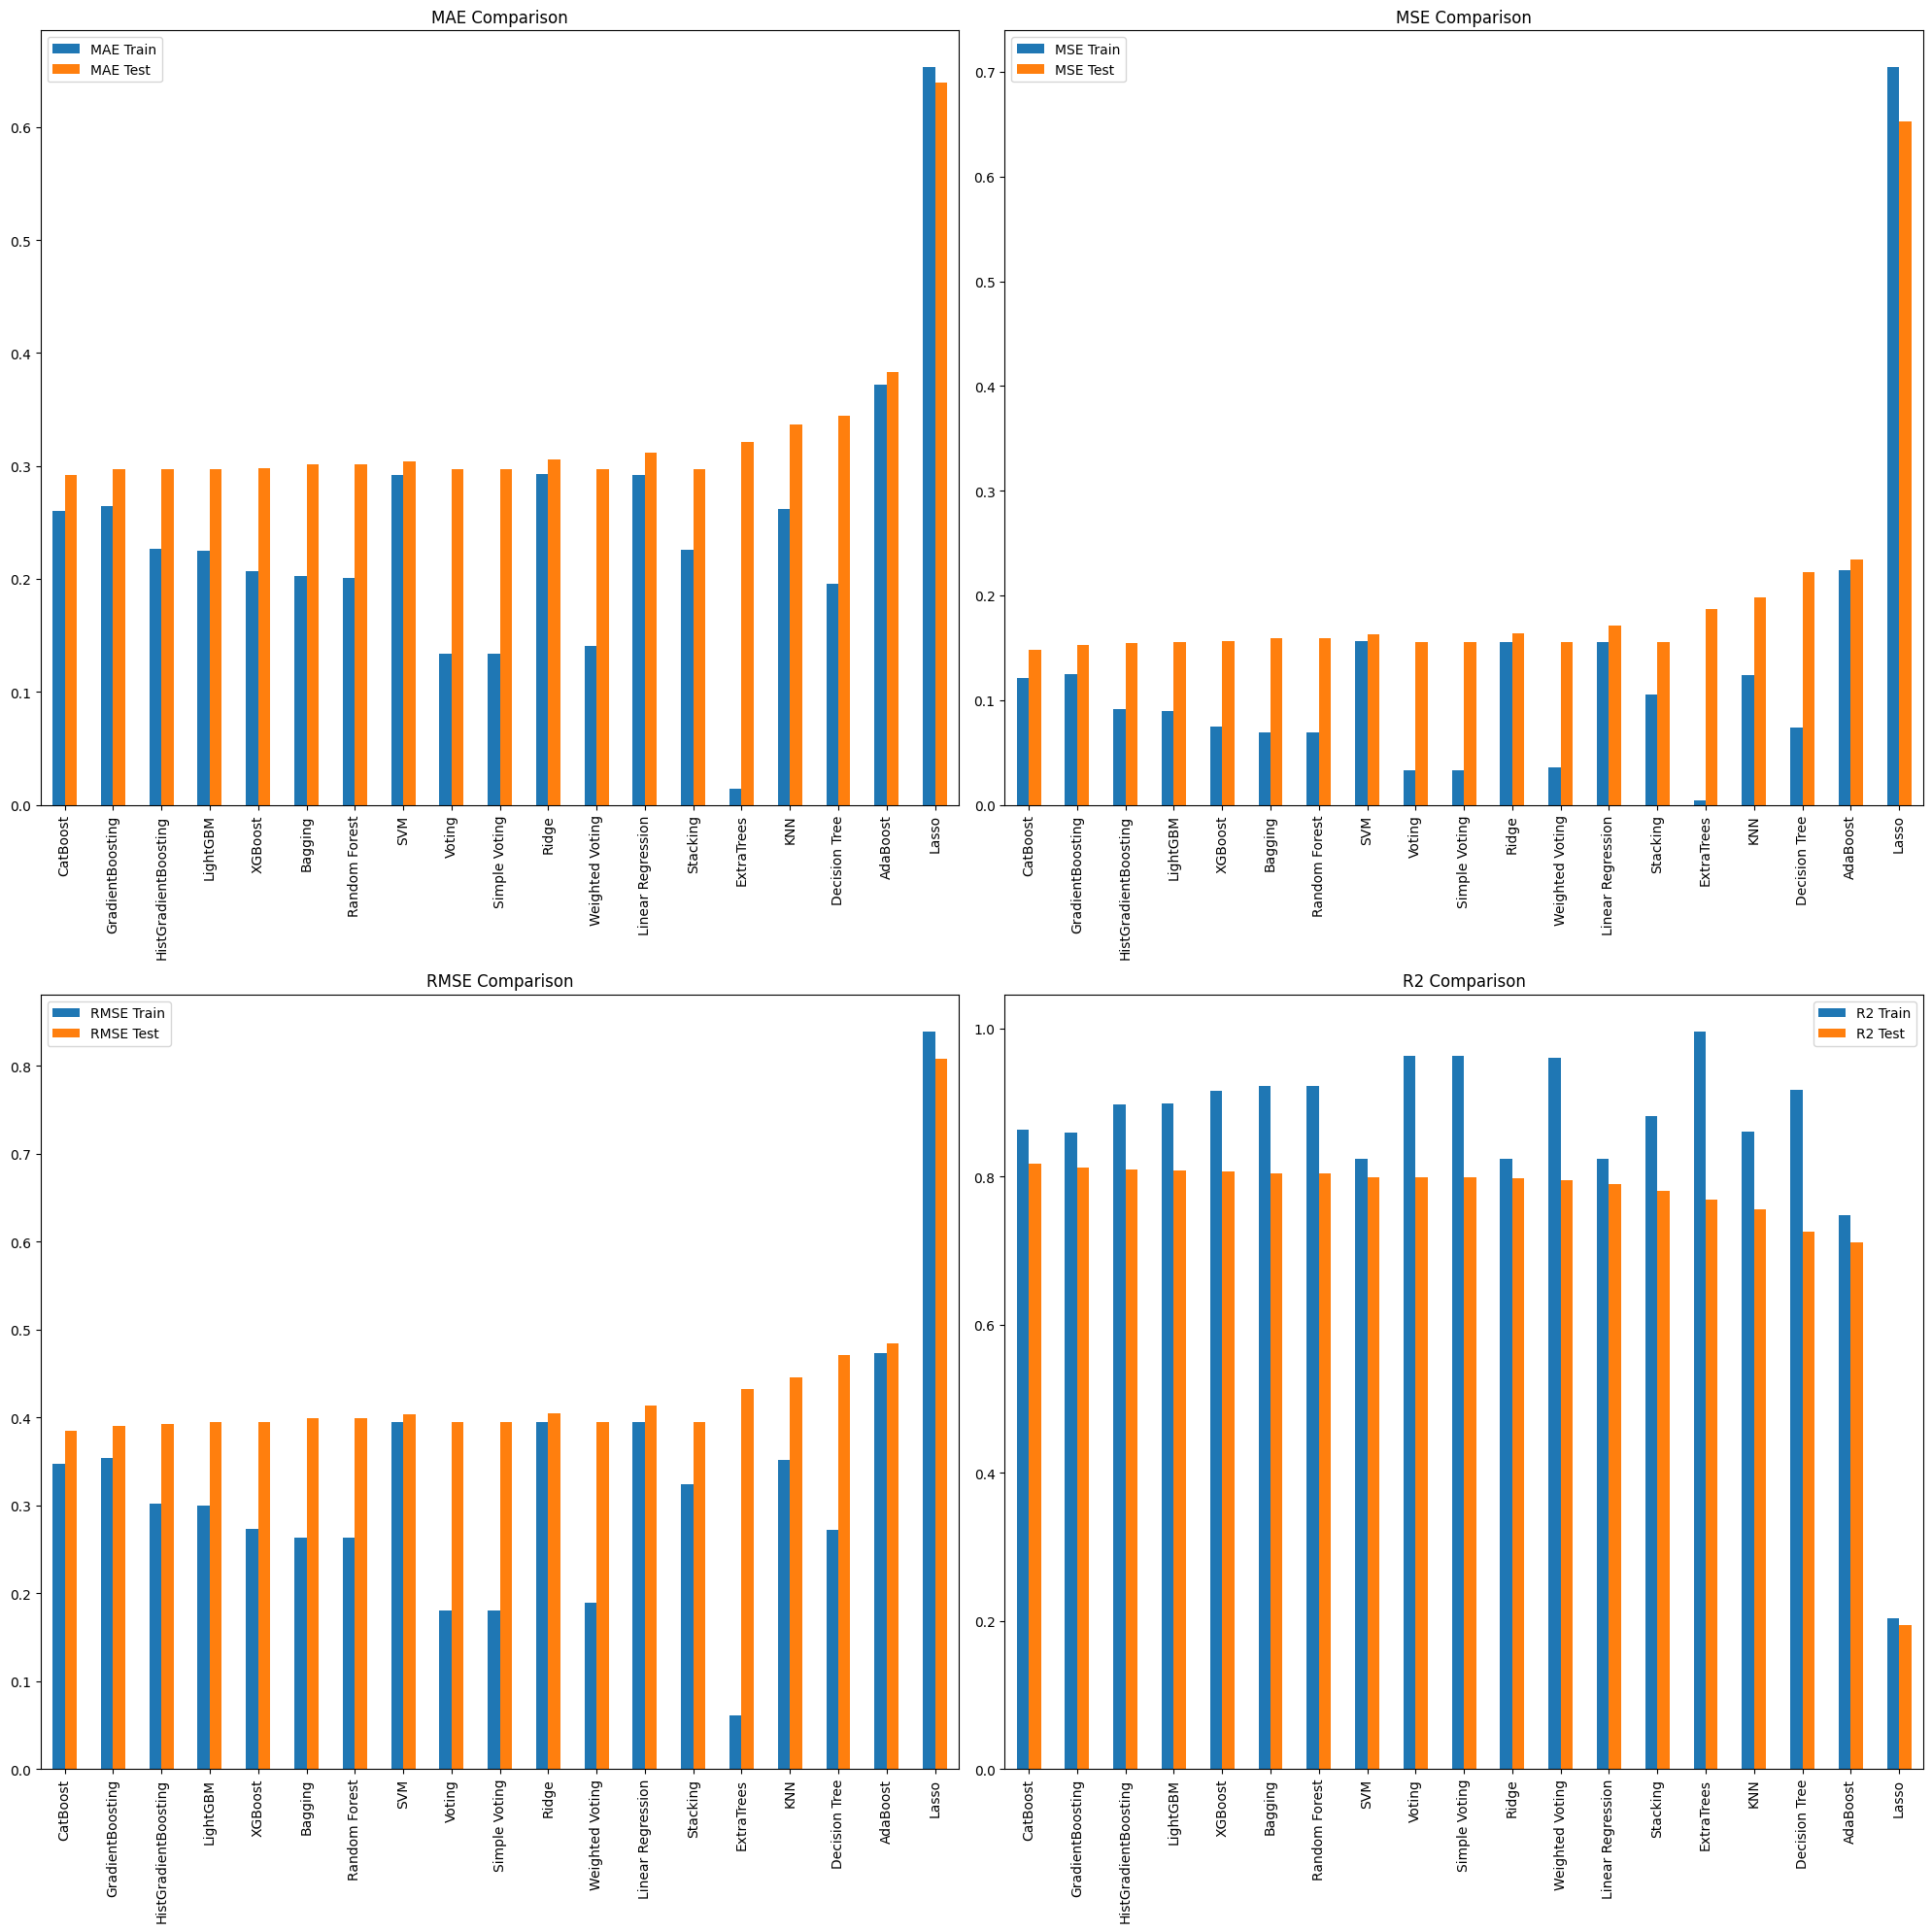

In [ ]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()